In [1]:
!python3 -m pip install torcheval

In [2]:
import os
import time
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive
from collections import namedtuple

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import default_collate, DataLoader, random_split

import torchvision.transforms as T
from torchvision.datasets import CelebA, FashionMNIST

from torcheval.metrics import FrechetInceptionDistance

In [3]:
class NoiseEmbedding(nn.Module):
    def __init__(self, cond_channels):
        super().__init__()
        self.register_buffer("weight", torch.randn(1, cond_channels // 2))

    def forward(self, input):
        f = 2 * torch.pi * input.unsqueeze(1) @ self.weight
        return torch.cat([f.cos(), f.sin()], dim=-1)


class CondBatchNorm2d(nn.Module):
    def __init__(self, nb_channels, cond_channels):
        super().__init__()
        self.cond_channels = cond_channels
        if cond_channels > 0:
            self.norm = nn.BatchNorm2d(nb_channels, affine=False)
            self.gamma = nn.Linear(cond_channels, nb_channels)
            self.beta = nn.Linear(cond_channels, nb_channels)
        else:
            self.norm = nn.BatchNorm2d(nb_channels)

    def forward(self, x, cond):
        y = self.norm(x)
        if self.cond_channels > 0:
            gamma = self.gamma(cond)[:, :, None, None]
            beta = self.beta(cond)[:, :, None, None]
            y = y * gamma + beta
        return y


class ZeroConv2d(nn.Module):
    def __init__(self, *args, zero_init=False, **kwargs):
        super().__init__()
        self.conv = nn.Conv2d(*args, **kwargs)
        if zero_init:
            self.conv.weight = torch.nn.Parameter(torch.zeros_like(self.conv.weight))
            self.conv.bias = torch.nn.Parameter(torch.zeros_like(self.conv.bias))

    def forward(self, input):
        return self.conv(input)


class CondResidualBlock(nn.Module):
    def __init__(self, nb_channels, cond_channels, zero_init):
        super().__init__()
        self.norm1 = CondBatchNorm2d(nb_channels, cond_channels)
        self.conv1 = ZeroConv2d(nb_channels, nb_channels, kernel_size=3, padding=1, zero_init=zero_init)
        self.norm2 = CondBatchNorm2d(nb_channels, cond_channels)
        self.conv2 = ZeroConv2d(nb_channels, nb_channels, kernel_size=3, padding=1, zero_init=zero_init)

    def forward(self, x, cond):
        y = self.conv1(F.relu(self.norm1(x, cond)))
        y = self.conv2(F.relu(self.norm2(y, cond)))
        return x + y


class CondResNet(nn.Module):
    def __init__(
        self,
        image_channels,
        nb_channels,
        num_blocks,
        cond_channels=0,
        zero_init=False,
    ):
        super().__init__()
        self.cond_channels = cond_channels
        if cond_channels > 0:
            self.noise_emb = NoiseEmbedding(cond_channels)
        self.conv_in = ZeroConv2d(image_channels, nb_channels, kernel_size=3, padding=1)
        self.blocks = nn.ModuleList(
            [CondResidualBlock(nb_channels, cond_channels, zero_init) for _ in range(num_blocks)]
        )
        self.conv_out = ZeroConv2d(nb_channels, image_channels, kernel_size=3, padding=1, zero_init=zero_init)

    def forward(self, noisy_input, c_noise):
        cond = None
        if self.cond_channels > 0:
            cond = self.noise_emb(c_noise)
        x = self.conv_in(noisy_input)
        for block in self.blocks:
            x = block(x, cond)
        return self.conv_out(x)


class CondUNetBlock(nn.Module):
    def __init__(self, in_channels, out_channels, cond_channels, zero_init=False):
        super().__init__()
        self.conv1 = ZeroConv2d(in_channels, out_channels, kernel_size=3, padding=1, zero_init=zero_init)
        self.norm1 = CondBatchNorm2d(out_channels, cond_channels)
        self.conv2 = ZeroConv2d(out_channels, out_channels, kernel_size=3, padding=1, zero_init=zero_init)
        self.norm2 = CondBatchNorm2d(out_channels, cond_channels)

    def forward(self, x, cond):
        y = F.relu(self.norm1(self.conv1(x), cond))
        y = F.relu(self.norm2(self.conv2(y), cond))
        return y


class CondUNet(nn.Module):
    def __init__(self, image_channels, features, cond_channels=0, zero_init=False):
        super().__init__()
        self.cond_channels = cond_channels
        if cond_channels > 0:
            self.noise_emb = NoiseEmbedding(cond_channels)
        self.encoder1 = CondUNetBlock(image_channels, features, cond_channels)
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)
        self.encoder2 = CondUNetBlock(features, features * 2, cond_channels)
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)
        self.encoder3 = CondUNetBlock(features * 2, features * 4, cond_channels)
        self.pool3 = nn.MaxPool2d(kernel_size=2, stride=2)
        self.encoder4 = CondUNetBlock(features * 4, features * 8, cond_channels)
        self.pool4 = nn.MaxPool2d(kernel_size=2, stride=2)
        self.bottleneck = CondUNetBlock(features * 8, features * 16, cond_channels)
        self.upconv4 = nn.ConvTranspose2d(features * 16, features * 8, kernel_size=2, stride=2)
        self.decoder4 = CondUNetBlock(features * 16, features * 8, cond_channels, zero_init)
        self.upconv3 = nn.ConvTranspose2d(features * 8, features * 4, kernel_size=2, stride=2)
        self.decoder3 = CondUNetBlock(features * 8, features * 4, cond_channels, zero_init)
        self.upconv2 = nn.ConvTranspose2d(features * 4, features * 2, kernel_size=2, stride=2)
        self.decoder2 = CondUNetBlock(features * 4, features * 2, cond_channels, zero_init)
        self.upconv1 = nn.ConvTranspose2d(features * 2, features, kernel_size=2, stride=2)
        self.decoder1 = CondUNetBlock(features * 2, features, cond_channels, zero_init)
        self.conv = ZeroConv2d(features, image_channels, kernel_size=1, zero_init=zero_init)

    def forward(self, noisy_input, c_noise):
        cond = None
        if self.cond_channels > 0:
            cond = self.noise_emb(c_noise)
        enc1 = self.encoder1(noisy_input, cond)
        enc2 = self.encoder2(self.pool1(enc1), cond)
        enc3 = self.encoder3(self.pool2(enc2), cond)
        enc4 = self.encoder4(self.pool3(enc3), cond)
        bottleneck = self.bottleneck(self.pool4(enc4), cond)
        dec4 = self.upconv4(bottleneck)
        dec4 = torch.cat((dec4, enc4), dim=1)
        dec4 = self.decoder4(dec4, cond)
        dec3 = self.upconv3(dec4)
        dec3 = torch.cat((dec3, enc3), dim=1)
        dec3 = self.decoder3(dec3, cond)
        dec2 = self.upconv2(dec3)
        dec2 = torch.cat((dec2, enc2), dim=1)
        dec2 = self.decoder2(dec2, cond)
        dec1 = self.upconv1(dec2)
        dec1 = torch.cat((dec1, enc1), dim=1)
        dec1 = self.decoder1(dec1, cond)
        return self.conv(dec1)

In [4]:
DataInfo = namedtuple("DataInfo", "image_channels image_size num_classes sigma_data")
DataLoaders = namedtuple("DataLoaders", "train valid")


def load_dataset_and_make_dataloaders(
    dataset_name,
    root_dir,
    batch_size,
    num_workers,
    pin_memory,
):
    train_dataset, valid_dataset, data_info = load_dataset(dataset_name, root_dir)
    dl = make_dataloaders(
        train_dataset,
        valid_dataset,
        data_info.num_classes,
        batch_size,
        num_workers,
        pin_memory,
    )
    return dl, data_info


def load_dataset(dataset_name, root_dir="data"):
    match dataset_name:
        case "FashionMNIST":
            t = T.Compose([T.ToTensor(), T.Pad(2), T.Normalize(mean=(0.5,), std=(0.5,))])
            train_dataset = FashionMNIST(root_dir, download=True, transform=t)
            train_dataset, valid_dataset = random_split(train_dataset, [50000, 10000])
            num_classes = 10
        case "CelebA":
            t = T.Compose(
                [
                    T.ToTensor(),
                    T.CenterCrop(178),
                    T.Resize(128, antialias=True),
                    T.Normalize(mean=(0.5,), std=(0.5,)),
                ]
            )
            train_dataset = CelebA(root_dir, download=True, transform=t)
            train_dataset, valid_dataset = random_split(train_dataset, [150000, 12770])
            num_classes = None
        case other:
            raise RuntimeError("Unknown dataset: " + other)
    x, _ = next(iter(DataLoader(train_dataset, batch_size=10000, shuffle=True)))
    _, c, h, w = x.size()
    sigma_data = x.std()
    return train_dataset, valid_dataset, DataInfo(c, h, num_classes, sigma_data)


def make_dataloaders(
    train_dataset,
    valid_dataset,
    num_classes,
    batch_size,
    num_workers,
    pin_memory,
):
    collate_fn = default_collate if num_classes is not None else lambda batch: (default_collate(batch)[0], None)
    kwargs = {
        "collate_fn": collate_fn,
        "num_workers": num_workers,
        "persistent_workers": (num_workers > 0),
        "pin_memory": pin_memory,
    }
    return DataLoaders(
        train=DataLoader(train_dataset, batch_size=batch_size, shuffle=True, **kwargs),
        valid=DataLoader(valid_dataset, batch_size=2 * batch_size, **kwargs),
    )

In [5]:
def build_sigma_schedule(steps, rho=7, sigma_min=2e-3, sigma_max=80):
    min_inv_rho = sigma_min ** (1 / rho)
    max_inv_rho = sigma_max ** (1 / rho)
    sigmas = (max_inv_rho + torch.linspace(0, 1, steps) * (min_inv_rho - max_inv_rho)) ** rho
    return sigmas

In [6]:
def make_c(sigma, sigma_data):
    ss = sigma**2
    sds = sigma_data**2
    sss = ss + sds
    ssss = torch.sqrt(sss)
    c_in = 1 / ssss
    c_out = sigma * sigma_data / ssss
    c_skip = sds / sss
    c_noise = torch.log(sigma) / 4
    return (
        c_in.view(-1, 1, 1, 1),
        c_out.view(-1, 1, 1, 1),
        c_skip.view(-1, 1, 1, 1),
        torch.atleast_1d(c_noise),
    )

In [7]:
def train_model(model, train, max_epochs, sigma_schedule, info):
    model.train()
    lr = 0.001
    loss_fn = torch.nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, factor=0.3, patience=3, threshold=0.001)
    for epoch in range(max_epochs):
        total_loss = 0
        total_time = 0
        for Y, _ in train:
            beg = time.perf_counter()
            X = Y.clone()
            sigmas = np.random.choice(sigma_schedule, X.shape[0])
            sigmas = torch.from_numpy(sigmas)
            for i, sigma in enumerate(sigmas):
                X[i] += torch.normal(0, sigma, X.shape[1:])
            c_in, c_out, c_skip, c_noise = make_c(sigmas, info.sigma_data)
            output = model((X * c_in).to("cuda"), c_noise.to("cuda"))
            target = (Y - X * c_skip) / c_out
            loss = loss_fn(output, target.to("cuda"))
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
            end = time.perf_counter()
            total_time += end - beg
        print(f"Epoch: {epoch + 1:02}, Loss: {total_loss / len(train):.3f}, Time: {total_time:.1f}, LR: {lr:.5f}")
        scheduler.step(total_loss)
        lr = scheduler._last_lr[0]
        if lr < 3e-5:
            break

In [8]:
def sample(model, size, sigma_schedule, info):
    model.eval()
    X = torch.normal(
        0,
        sigma_schedule[0],
        [size, info.image_channels, info.image_size, info.image_size],
    )
    for i, sigma in enumerate(sigma_schedule):
        c_in, c_out, c_skip, c_noise = make_c(sigma, info.sigma_data)
        sigma_next = 0 if i == len(sigma_schedule) - 1 else sigma_schedule[i + 1]
        with torch.no_grad():
            X_denoised = c_skip * X + c_out * model((X * c_in).to("cuda"), c_noise.to("cuda")).to("cpu")
        d = (X - X_denoised) / sigma
        X = X + d * (sigma_next - sigma)
    return X

In [9]:
def save_model(model, name):
    root = "/content/drive/MyDrive/models"
    os.makedirs(root, exist_ok=True)
    torch.save(model, f"{root}/{name}.pt")

In [10]:
def load_model(name):
    return torch.load(f"/content/drive/MyDrive/models/{name}.pt")

In [11]:
def plot(X, m):
    fig, ax = plt.subplots(m, m, figsize=(20, 20), gridspec_kw={"wspace": 0.01, "hspace": 0.01})
    for i in range(m):
        for j in range(m):
            ax[i][j].axis("off")
            ax[i][j].imshow(X[m * i + j], cmap="gray")
    plt.tight_layout()
    plt.show()

In [12]:
def compute_fid(model, FID, test, batches, size, sigma_schedule, info):
    model.eval()
    for Y, _ in test:
        FID.update(Y.add(1).div(2).repeat(1, 3, 1, 1), True)
    for _ in range(batches):
        X = sample(model, size, sigma_schedule, info)
        X = X.clamp(-1, 1).add(1).div(2)
        X = X.repeat(1, 3, 1, 1)
        FID.update(X, False)
    fid = FID.compute()
    return fid.item()

In [13]:
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [25]:
[train, test], info = load_dataset_and_make_dataloaders(
    "FashionMNIST", root_dir="data", batch_size=256, num_workers=4, pin_memory=True
)

In [15]:
resNet = CondResNet(info.image_channels, 128, 10).to("cuda")
condResNet = CondResNet(info.image_channels, 128, 10, 32).to("cuda")
zeroResNet = CondResNet(info.image_channels, 128, 10, 32, True).to("cuda")
unet = CondUNet(info.image_channels, 16).to("cuda")
condUNet = CondUNet(info.image_channels, 16, 32).to("cuda")
zeroUNet = CondUNet(info.image_channels, 16, 32, True).to("cuda")

In [16]:
models = [
    ["ResNet", resNet],
    ["CondResNet", condResNet],
    ["ZeroResNet", zeroResNet],
    ["UNet", unet],
    ["CondUNet", condUNet],
    ["ZeroUNet", zeroUNet],
]

In [17]:
sigma_schedule = build_sigma_schedule(50)

In [18]:
for name, model in models:
    params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(name, "has", params, "trainable parameters", end="\n\n")
    train_model(model, train, 99, sigma_schedule, info)
    save_model(model, name)
    print(end="\n\n\n")

ResNet has 2959233 trainable parameters

Epoch: 01, Loss: 5.146, Time: 66.1, LR: 0.00100
Epoch: 02, Loss: 0.558, Time: 65.5, LR: 0.00100
Epoch: 03, Loss: 0.512, Time: 65.3, LR: 0.00100
Epoch: 04, Loss: 0.485, Time: 65.3, LR: 0.00100
Epoch: 05, Loss: 0.466, Time: 65.3, LR: 0.00100
Epoch: 06, Loss: 0.451, Time: 65.3, LR: 0.00100
Epoch: 07, Loss: 0.444, Time: 65.4, LR: 0.00100
Epoch: 08, Loss: 0.438, Time: 65.2, LR: 0.00100
Epoch: 09, Loss: 0.432, Time: 65.3, LR: 0.00100
Epoch: 10, Loss: 0.424, Time: 65.3, LR: 0.00100
Epoch: 11, Loss: 0.421, Time: 65.2, LR: 0.00100
Epoch: 12, Loss: 0.417, Time: 65.3, LR: 0.00100
Epoch: 13, Loss: 0.414, Time: 65.3, LR: 0.00100
Epoch: 14, Loss: 0.410, Time: 65.3, LR: 0.00100
Epoch: 15, Loss: 0.408, Time: 65.3, LR: 0.00100
Epoch: 16, Loss: 0.409, Time: 65.4, LR: 0.00100
Epoch: 17, Loss: 0.402, Time: 65.5, LR: 0.00100
Epoch: 18, Loss: 0.400, Time: 65.4, LR: 0.00100
Epoch: 19, Loss: 0.397, Time: 65.4, LR: 0.00100
Epoch: 20, Loss: 0.395, Time: 65.4, LR: 0.00100

In [21]:
FID = FrechetInceptionDistance()
FID = FID.to("cuda")

In [26]:
for name, model in models:
    model = load_model(name)
    model = model.to("cuda")
    fid = compute_fid(model, FID, test, 78, 128, sigma_schedule, info)
    print(f"{name} FID score: {fid:.2f}")

ResNet FID score: 32.97
CondResNet FID score: 30.75
ZeroResNet FID score: 29.86
UNet FID score: 30.37
CondUNet FID score: 30.77
ZeroUNet FID score: 31.02


ResNet


<ipython-input-11-c9dde9036cea>:7: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


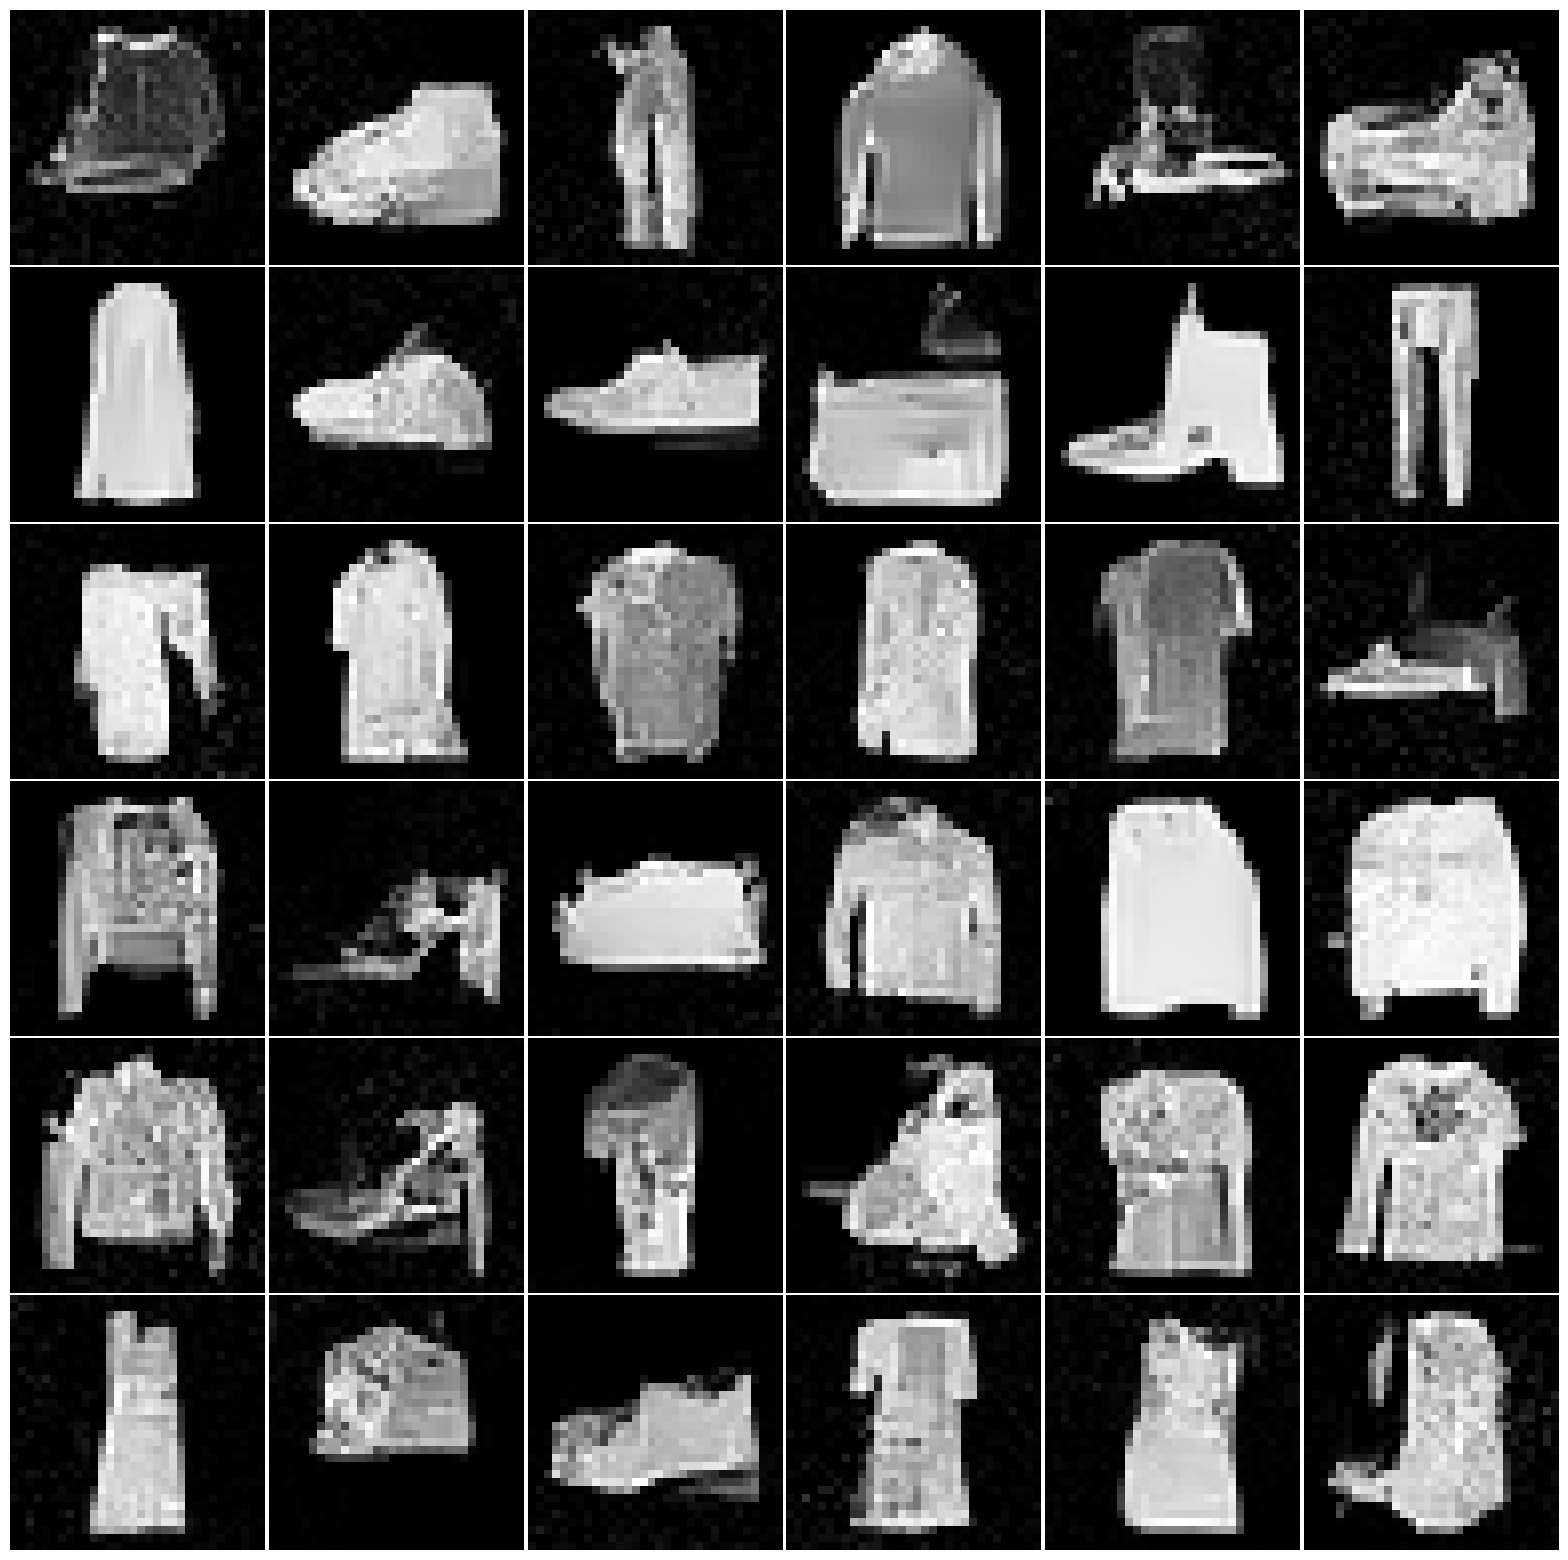

CondResNet


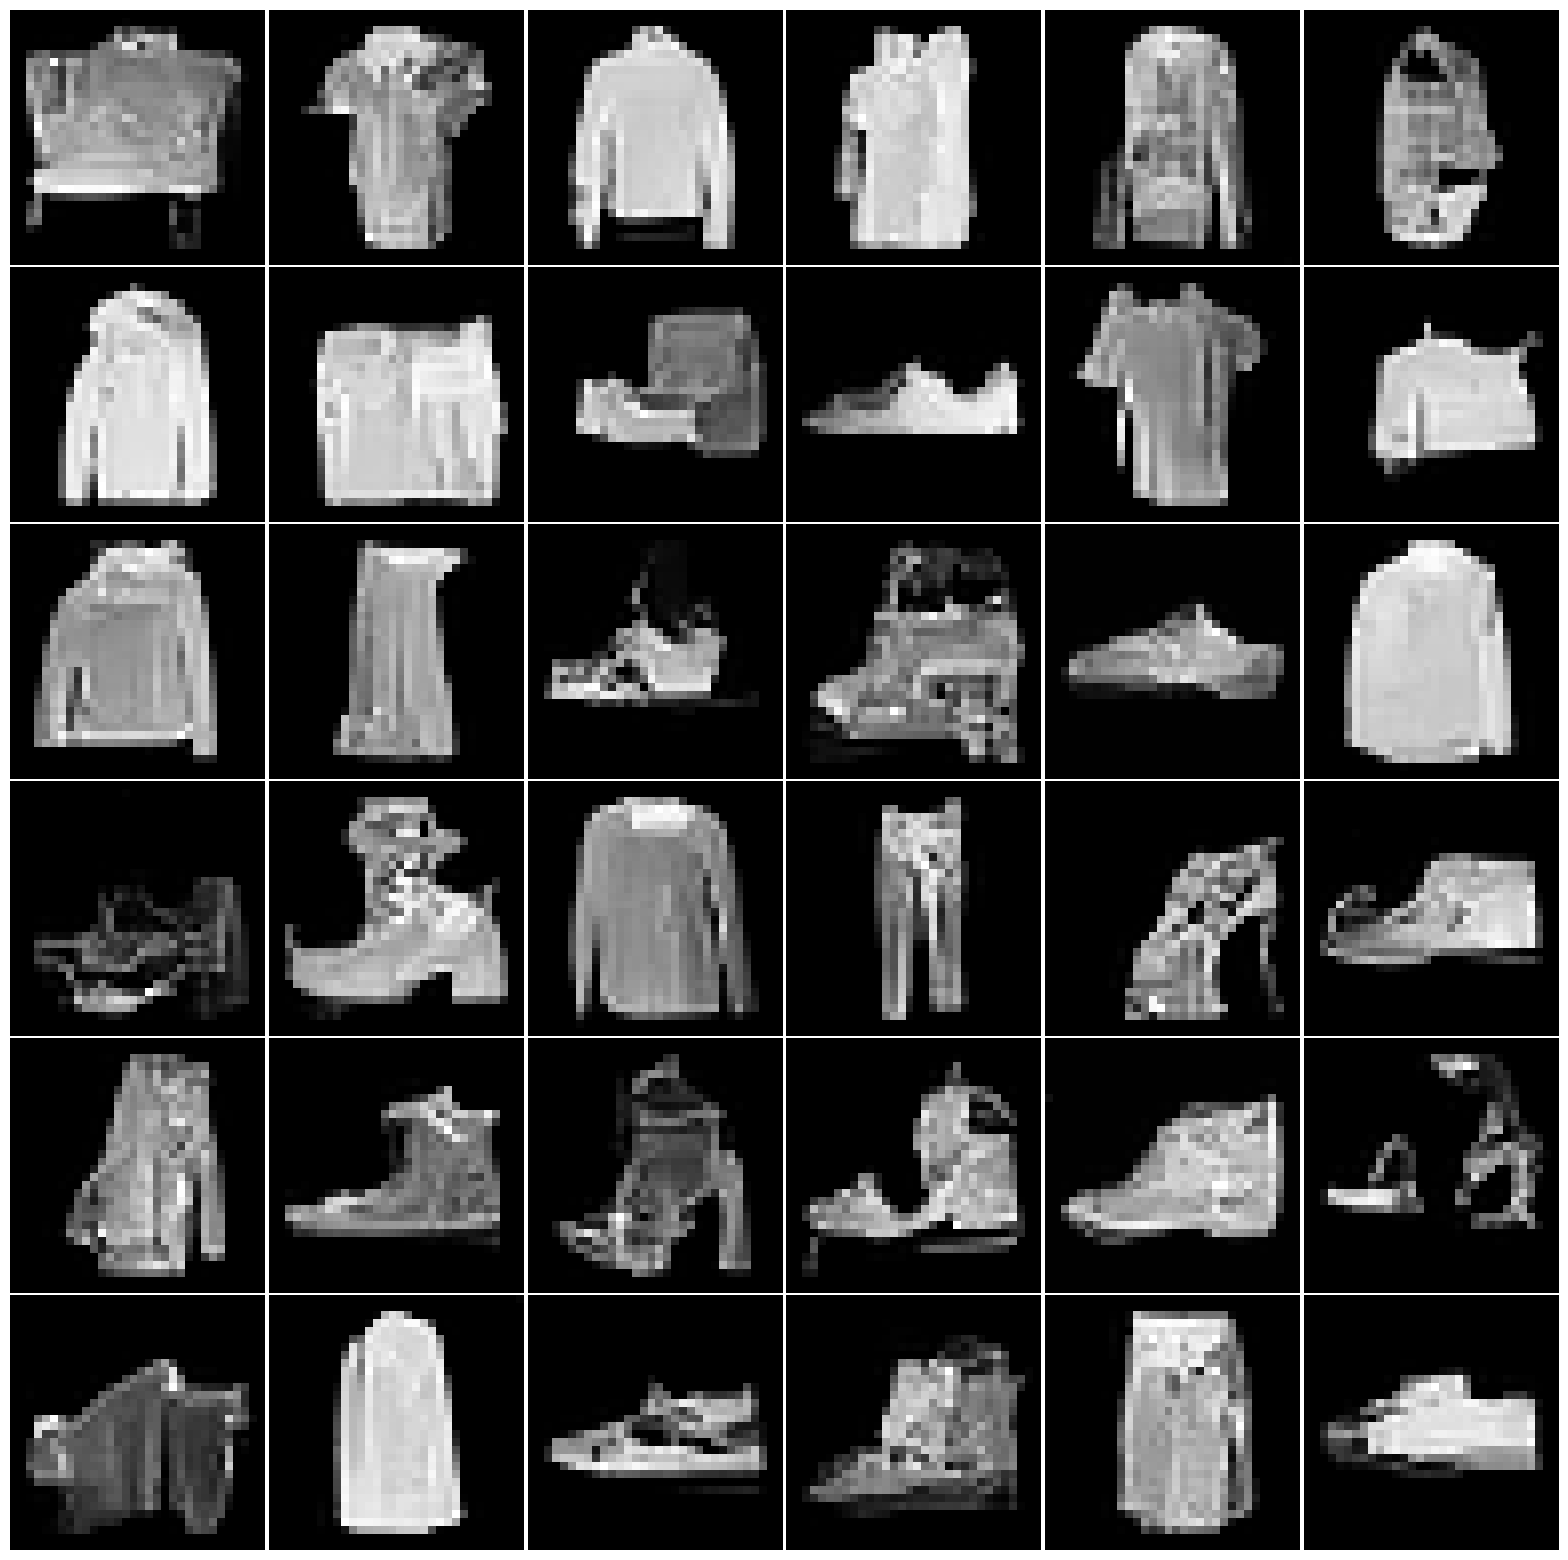

ZeroResNet


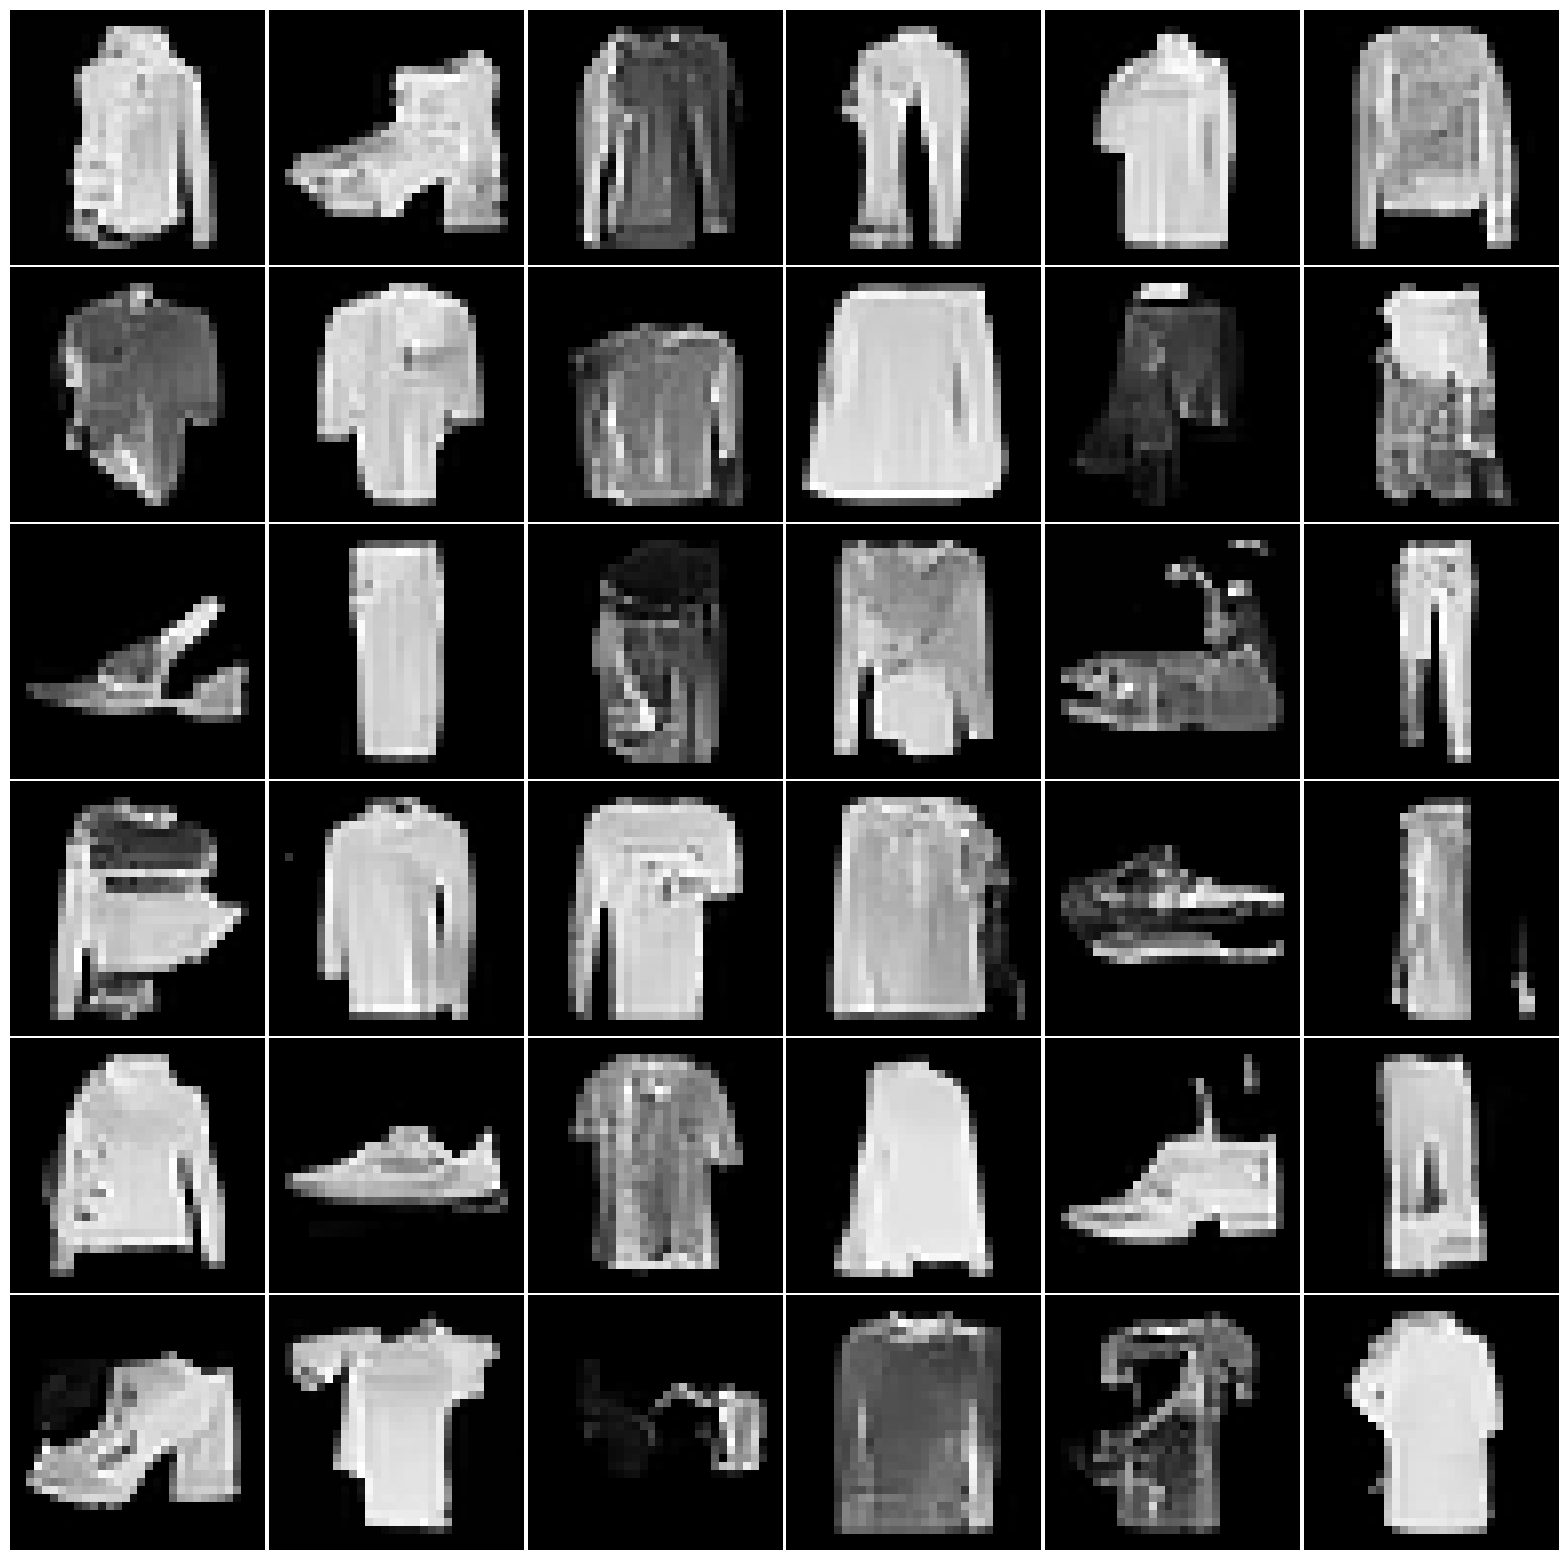

UNet


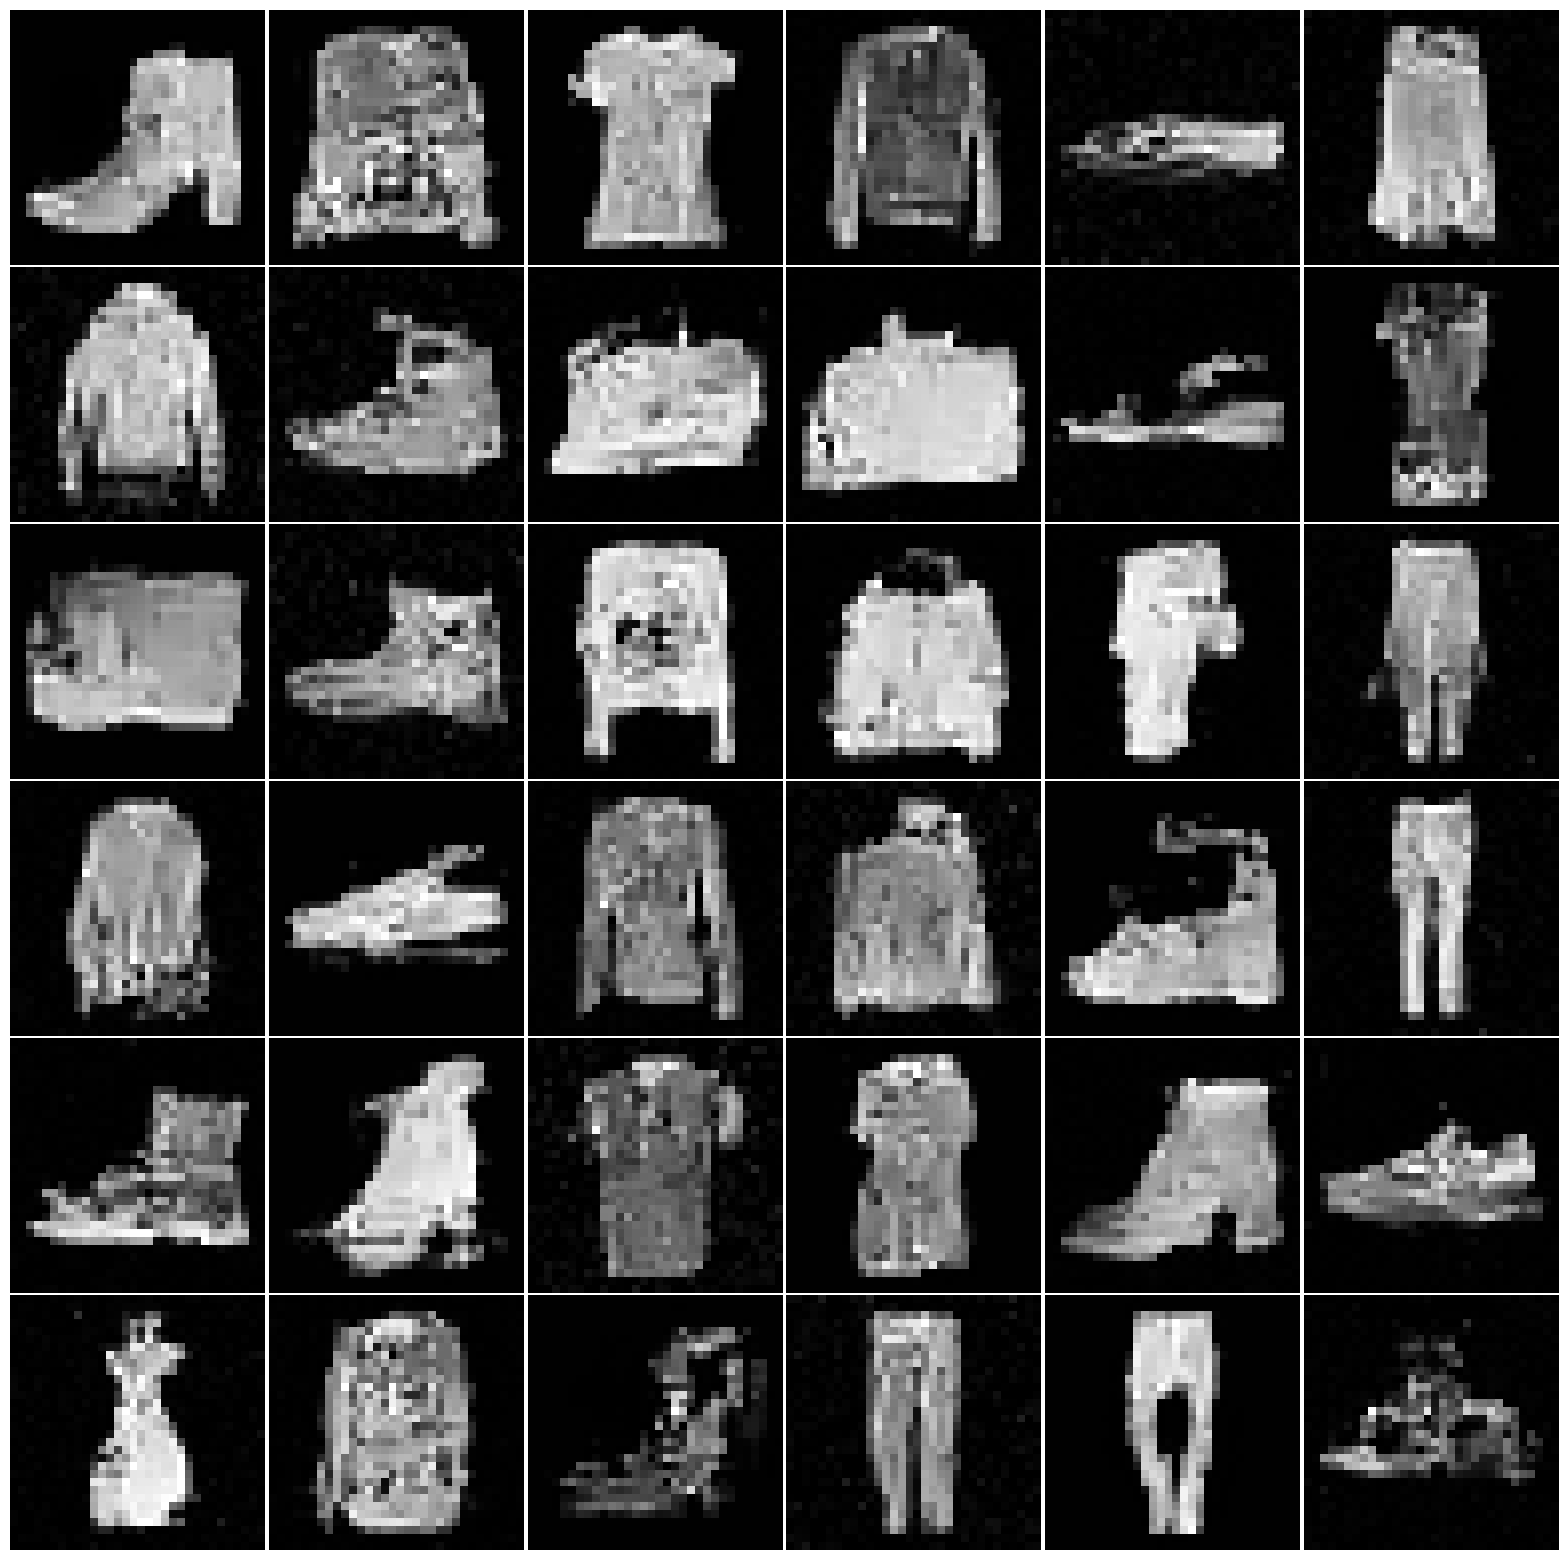

CondUNet


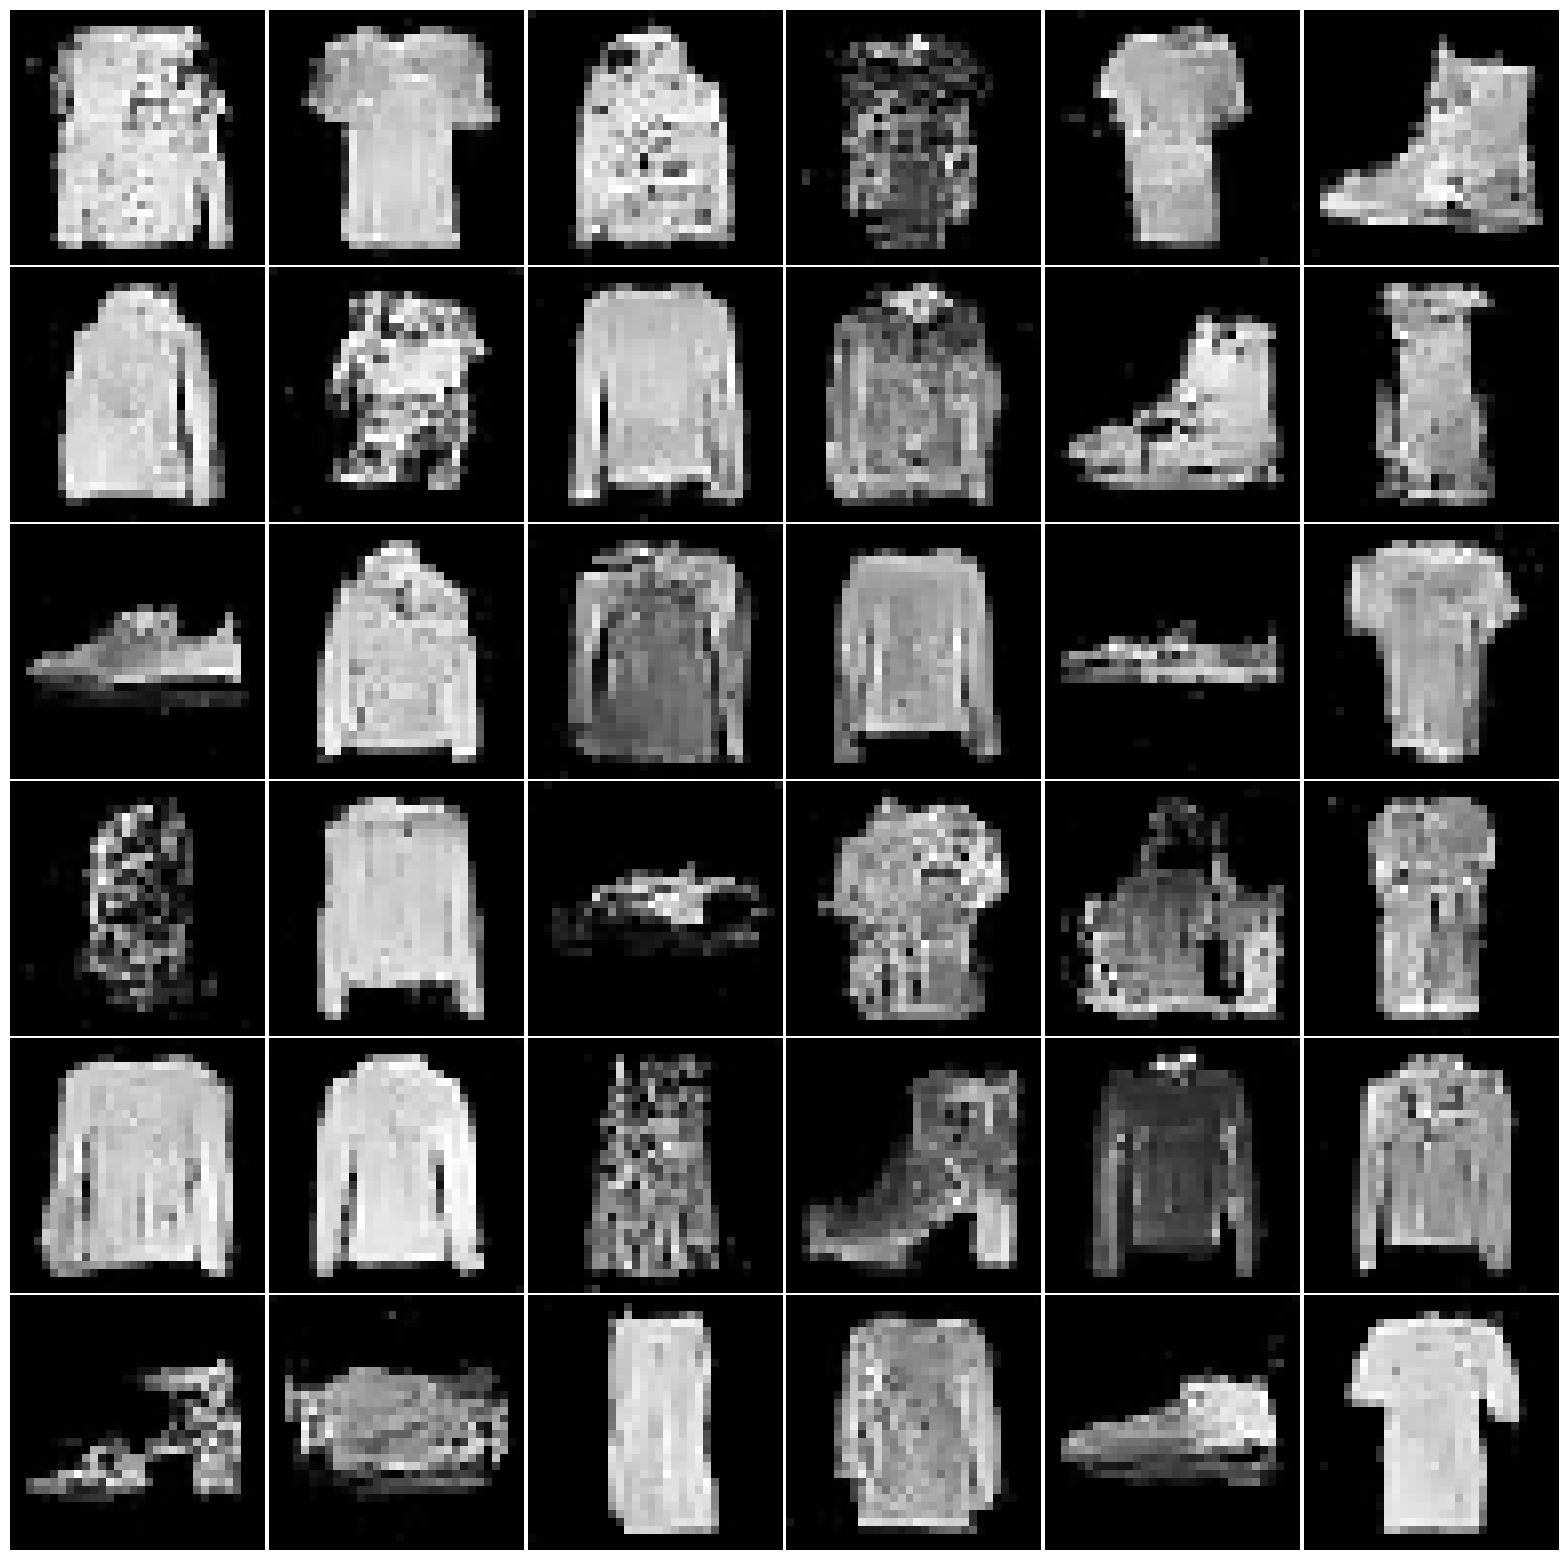

ZeroUNet


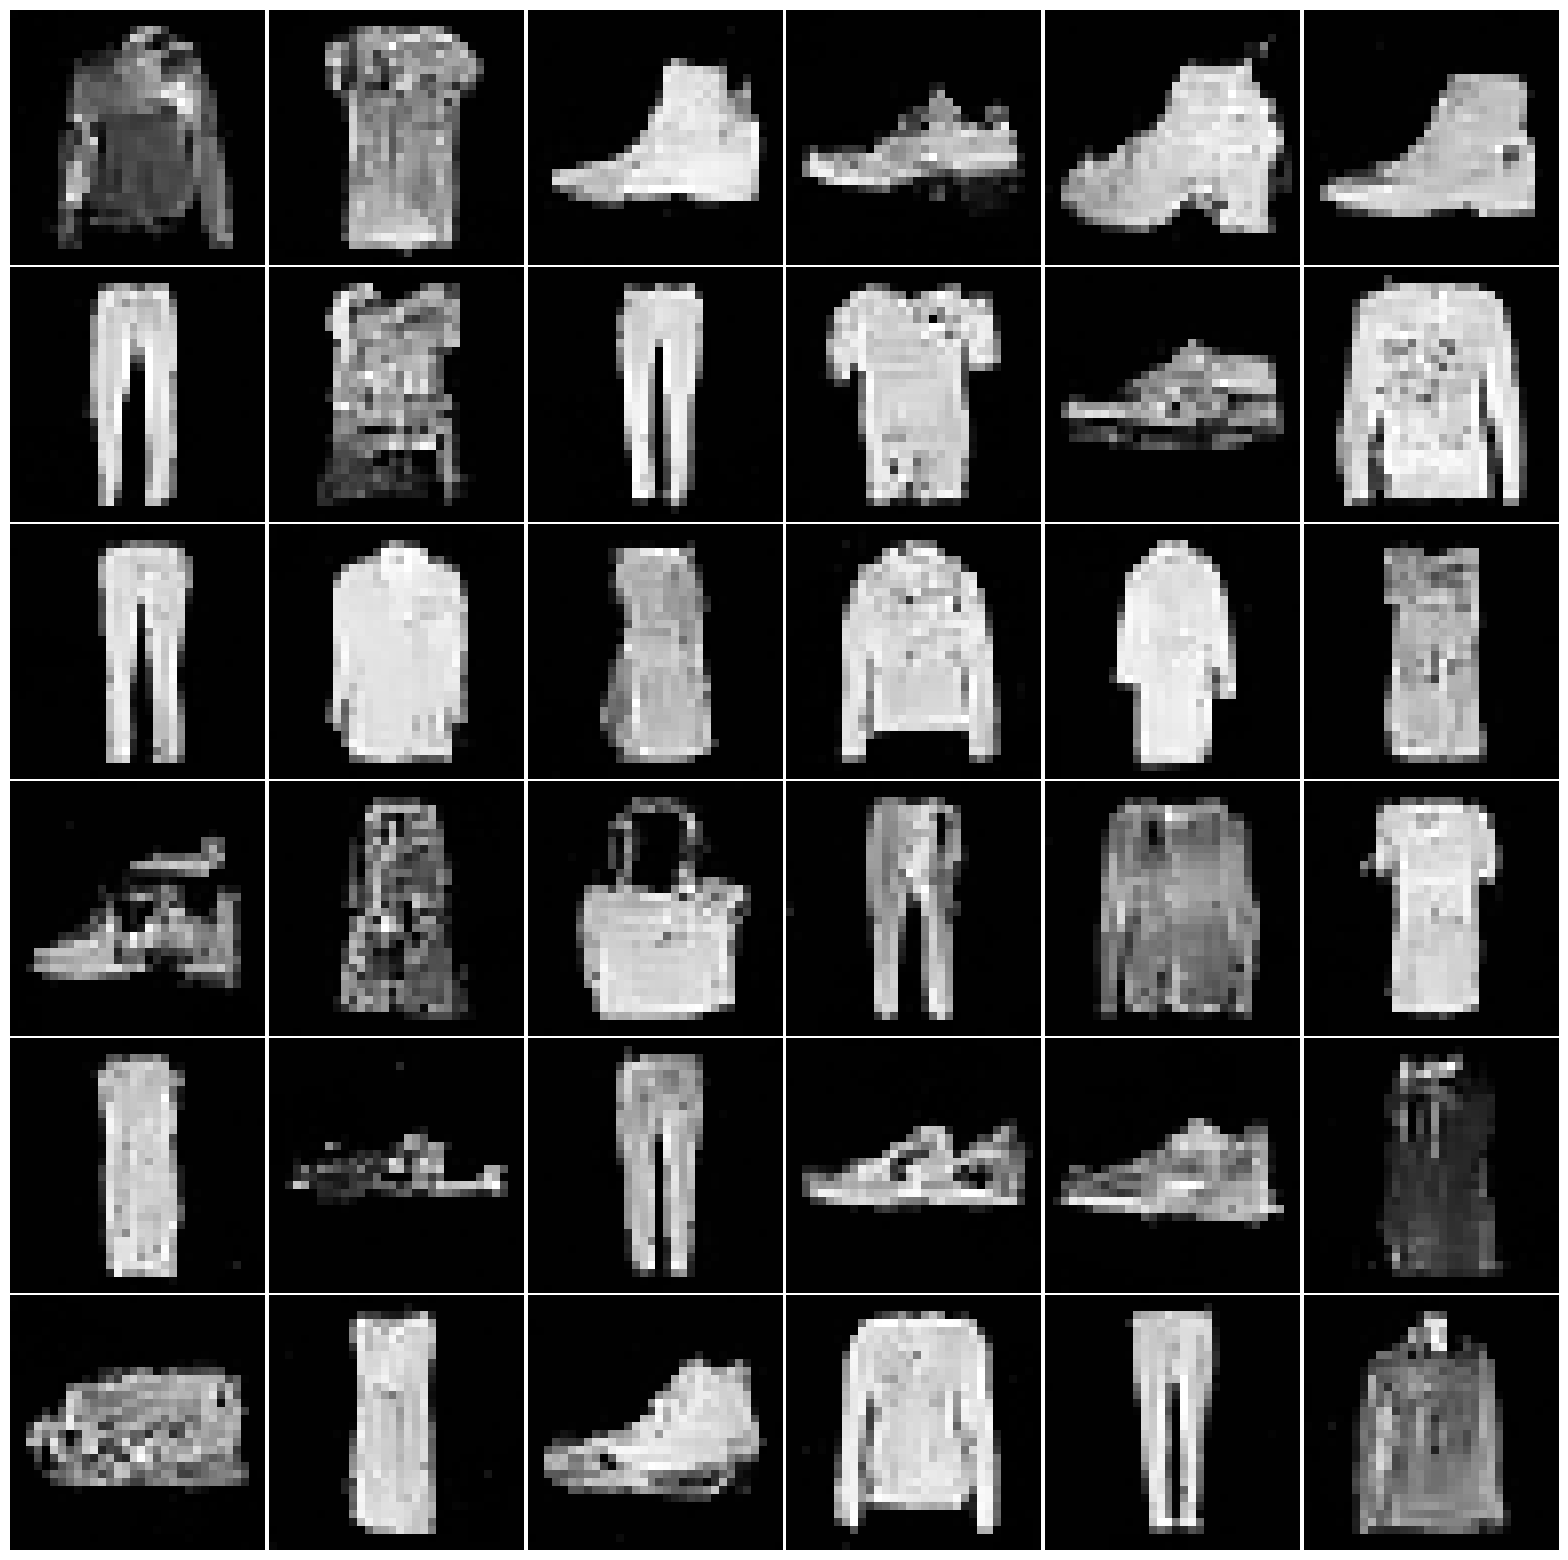

In [27]:
m = 6
for name, model in models:
    model = load_model(name)
    model = model.to("cuda")
    X = sample(model, m**2, sigma_schedule, info)
    X = X.clamp(-1, 1).add(1).div(2).mul(255).byte()
    X = X.permute(0, 2, 3, 1)
    print(name)
    plot(X, m)